In [35]:
# claudio-i@ace.me

In [1]:

import numpy as np
import pandas as pd
from scipy.io import loadmat
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import savgol_filter
import matplotlib.ticker as mticker
from multitaper import MTSpec

In [2]:
import pickle

with open('/home/cl/Google/@doctorado-sync/database/wind-cs/cs-wind_timeseries.pkl', 'rb') as f:
  cs = pickle.load(f)

In [3]:
import numpy as np
theta = np.deg2rad(cs['wind_dir_deg'].astype(float))
# Convert speed from knots to m/s
W = cs['wind_speed_kt'].astype(float) * 0.514444
# Meteorological convention (FROM): minus signs
cs['u'] = -W * np.sin(theta)   # +u is toward east
cs['v'] = -W * np.cos(theta)   # +v is toward north
cs['speed_ms'] = cs['wind_speed_kt'].astype(float) * 0.514444
del W, theta
cs

,time,wind_dir_deg,wind_speed_kt,vrb,source_file,u,v,speed_ms
0,2004-01-01 00:00:00,20.0,9.0,False,200401.html,-1.583552,-4.350773e+00,4.629996
1,2004-01-01 01:00:00,20.0,4.0,False,200401.html,-0.703801,-1.933677e+00,2.057776
2,2004-01-01 02:00:00,20.0,4.0,False,200401.html,-0.703801,-1.933677e+00,2.057776
3,2004-01-01 03:00:00,20.0,3.0,False,200401.html,-0.527851,-1.450258e+00,1.543332
4,2004-01-01 04:00:00,90.0,3.0,False,200401.html,-1.543332,-9.450183e-17,1.543332
...,...,...,...,...,...,...,...,...
26278,2006-12-31 19:00:00,250.0,14.0,False,200612.html,6.767869,2.463303e+00,7.202216
26279,2006-12-31 20:00:00,230.0,13.0,False,200612.html,5.123131,4.298817e+00,6.687772
26280,2006-12-31 21:00:00,230.0,13.0,False,200612.html,5.123131,4.298817e+00,6.687772
26281,2006-12-31 22:00:00,240.0,19.0,False,200612.html,8.464910,4.887218e+00,9.774436


In [4]:
pwd

'/home/cl/Google/@doctorado-sync/codes/adcp-l1'

In [5]:
cd '/home/cl/Google/@doctorado-sync/codes'

/home/cl/Google/@doctorado-sync/codes


In [6]:
import numpy as np

def pca_time_depth(X):
    """
    X: array (ntime, ndepth). Returns PCs, EOFs, variance fraction.
    - Demeans each depth column.
    - Fills NaNs with 0 after demeaning (i.e., column mean).
    - Uses SVD on anomalies.
    """
    X = np.asarray(X, dtype=float)
    ntime, ndepth = X.shape

    # anomalies (demean columns)
    col_mean = np.nanmean(X, axis=0)
    Xa = X - col_mean

    # fill NaNs with 0 (column mean after demeaning)
    Xa = np.where(np.isnan(Xa), 0.0, Xa)

    # SVD: Xa = U S V^T
    U, S, VT = np.linalg.svd(Xa, full_matrices=False)
    V = VT.T

    # PCs (time series) and EOFs (vertical modes)
    PCs = U @ np.diag(S)          # (ntime, r)
    EOFs = V                      # (ndepth, r)

    # variance explained
    total_var = np.sum(np.var(Xa, axis=0, ddof=1))
    mode_var = (S**2) / (ntime - 1)
    var_frac = mode_var / total_var           # fraction per mode
    var_pct = 100 * var_frac

    return PCs, EOFs, var_frac, var_pct

In [7]:
import pickle

with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataA_h.pkl', 'rb') as f:
    dataA = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataB_h.pkl', 'rb') as f:
    dataB = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataC_h.pkl', 'rb') as f:
    dataC = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataD_h.pkl', 'rb') as f:
    dataD = pickle.load(f)
with open('/home/cl/Google/@doctorado-sync/database/adcp-l1/dataE_h.pkl', 'rb') as f:
    dataE = pickle.load(f)

In [8]:
dataB

{'time': DatetimeIndex(['2005-01-15 13:00:00', '2005-01-15 14:00:00',
                '2005-01-15 15:00:00', '2005-01-15 16:00:00',
                '2005-01-15 17:00:00', '2005-01-15 18:00:00',
                '2005-01-15 19:00:00', '2005-01-15 20:00:00',
                '2005-01-15 21:00:00', '2005-01-15 22:00:00',
                ...
                '2005-01-25 06:00:00', '2005-01-25 07:00:00',
                '2005-01-25 08:00:00', '2005-01-25 09:00:00',
                '2005-01-25 10:00:00', '2005-01-25 11:00:00',
                '2005-01-25 12:00:00', '2005-01-25 13:00:00',
                '2005-01-25 14:00:00', '2005-01-25 15:00:00'],
               dtype='datetime64[ns]', name='datetime', length=243, freq='h'),
 'u': array([[ -28.77777863,  -39.22222137,  -30.66666603, ...,  220.777771  ,
          286.55554199,  398.        ],
        [ -63.        ,  -62.25      ,  -71.08333588, ...,  242.75      ,
          532.33331299, 1457.        ],
        [ -32.41666794,  -30.        , 

In [9]:
zdoy = dataB['time'].day
zidx = pd.unique(zdoy)
zidx

array([15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25], dtype=int32)

In [12]:
t1 = dataB['time']

In [13]:
u = dataB['u']
v = dataB['v']

In [14]:
def progressive_vector(u_mm_s, v_mm_s, time_index, break_on_gaps=True):
    """
    Compute progressive displacements (x_km, y_km) from u, v (mm/s) over time.

    Parameters
    ----------
    u_mm_s, v_mm_s : array-like or pandas Series
        Eastward (u) and northward (v) velocity components in mm/s.
    time_index : pandas.DatetimeIndex (or array convertible to it)
        Timestamps corresponding to u, v samples.
    break_on_gaps : bool
        If True, returns a mask to break the plot at data gaps (>1.5 * median dt).

    Returns
    -------
    x_km, y_km : np.ndarray
        Cumulative displacements in kilometers.
    segments_mask : np.ndarray of bool
        True where segment is continuous (useful to break the line on gaps).
    """
    # Ensure pandas objects
    t = pd.DatetimeIndex(time_index)
    u = pd.Series(u_mm_s, index=t, dtype='float64')
    v = pd.Series(v_mm_s, index=t, dtype='float64')

    # Align & remove rows where either component is NaN
    uv = pd.concat([u.rename('u'), v.rename('v')], axis=1)
    valid = uv.notna().all(axis=1)
    uv = uv[valid]
    t = uv.index

    if len(t) < 2:
        raise ValueError("Not enough valid samples after removing NaNs.")

    # Irregular sampling supported: compute dt (seconds) between samples
    dt_s = np.diff(t.view('int64')) / 1e9  # ns -> s

    # Optionally detect big gaps to break the line later
    if break_on_gaps:
        med = np.median(dt_s)
        gap_thresh = 1.5 * med if np.isfinite(med) and med > 0 else np.inf
        # segments_mask length must equal number of steps; prepend True for first point
        seg_ok = np.concatenate([[True], dt_s <= gap_thresh])
    else:
        seg_ok = np.ones(len(t), dtype=bool)

    # Convert mm/s -> m/s
    u_ms = uv['u'].to_numpy() / 1000.0
    v_ms = uv['v'].to_numpy() / 1000.0

    # Displacements per step (meters) using dt between consecutive samples.
    # Pad dt to align with samples (first step assumed same dt as first diff for simplicity).
    dt_aligned = np.concatenate([[dt_s[0]], dt_s])

    dx_m = u_ms * dt_aligned
    dy_m = v_ms * dt_aligned

    # Cumulative sum -> position (meters), then to km
    x_km = np.cumsum(dx_m) / 1000.0
    y_km = np.cumsum(dy_m) / 1000.0

    return x_km, y_km, seg_ok, t

In [18]:
t1 = dataB['time']
doy = t1.dayofyear
idx = pd.unique(doy)

doyZ = t1.day
idxZ = pd.unique(doyZ)

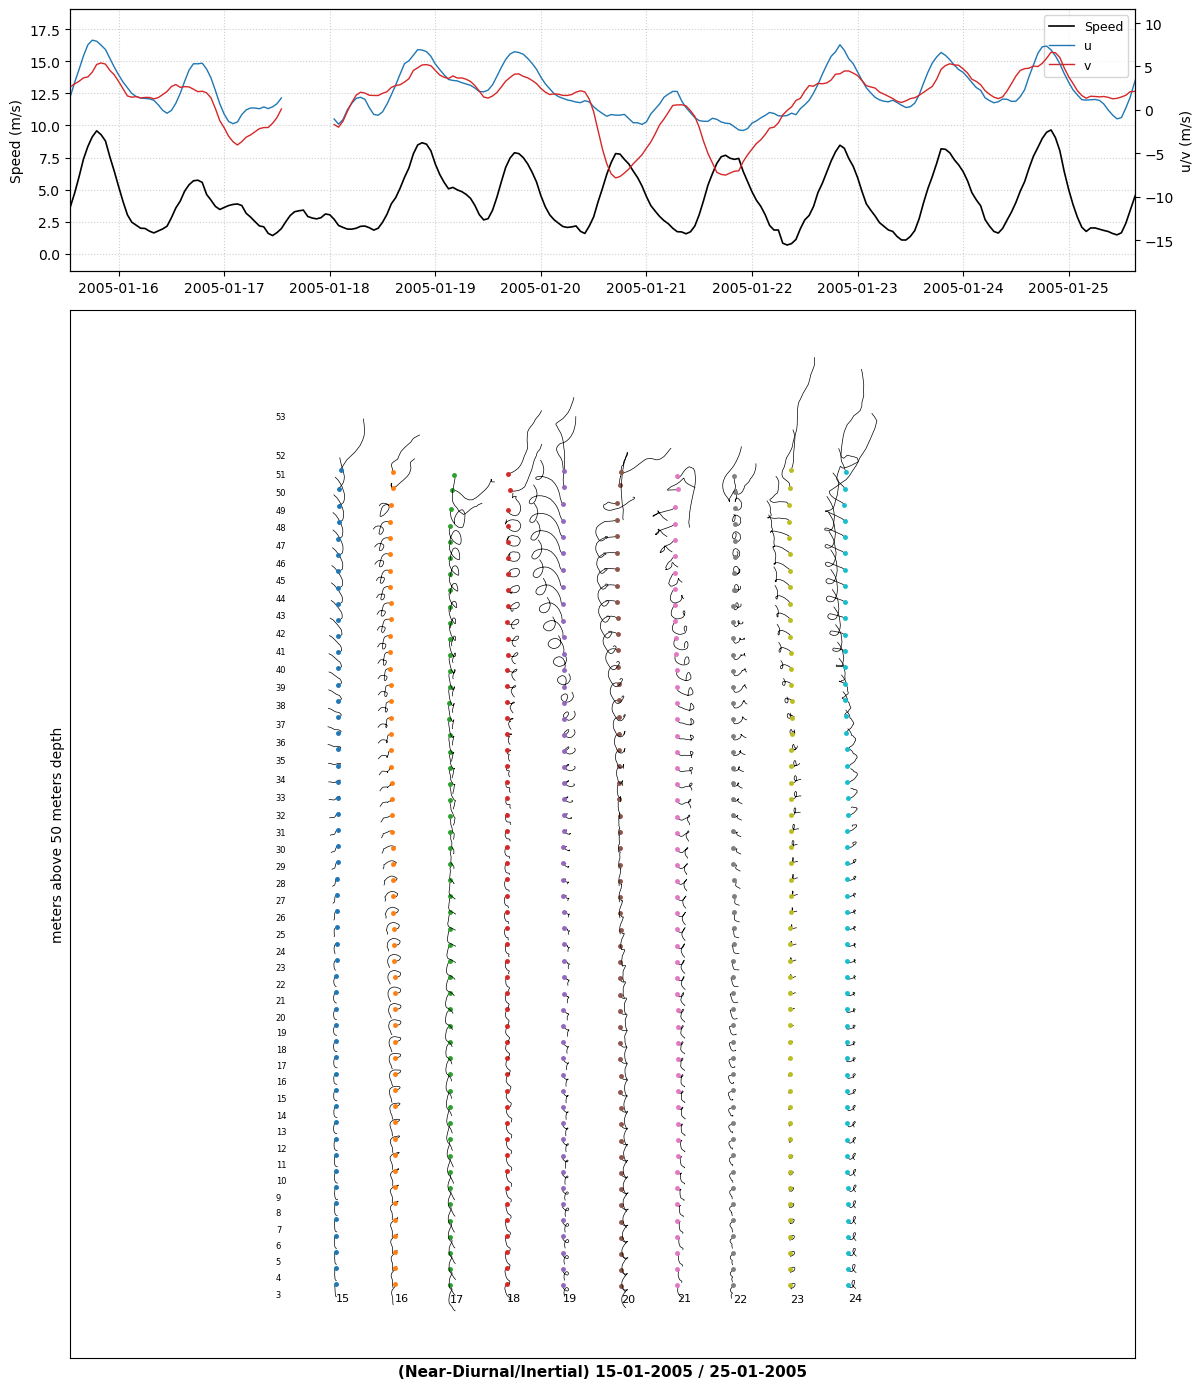

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import savgol_filter

# Create single figure with 2 vertically stacked subplots
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(12, 14),
    gridspec_kw={"height_ratios": [1, 4]},
    tight_layout=True,
)

# ==========================================
# TOP SUBPLOT: Time Series (Speed, U, V)
# ==========================================
# Left Y-axis: Total speed
line1 = ax1.plot(
    cs["time"],
    savgol_filter(cs["speed_ms"], 10, 2),
    color="black",
    linewidth=1.2,
    label="Speed",
)
ax1.set_ylabel("Speed (m/s)", color="black")
ax1.tick_params(axis="y", labelcolor="black")

# Right Y-axis: U and V components
ax1_twin = ax1.twinx()
line2 = ax1_twin.plot(
    cs["time"],
    savgol_filter(cs["u"], 10, 2),
    color="tab:blue",
    linewidth=1.0,
    label="u",
)
line3 = ax1_twin.plot(
    cs["time"],
    savgol_filter(cs["v"], 10, 2),
    color="tab:red",
    linewidth=1.0,
    label="v",
)
ax1_twin.set_ylabel("u/v (m/s)")

# Combined legend for top subplot
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right", frameon=True, fontsize=9)

ax1.set_xlim([dataB["time"][0], dataB["time"][-1]])
ax1.grid(True, linestyle=":", alpha=0.6)

# ==========================================
# BOTTOM SUBPLOT: Progressive Vector Diagram Waterfall
# ==========================================
for g in range(0, 51):
    for i in range(0, len(idx) - 1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u[z, g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(
                u[z, g], v[z, g], t1[z]
            )
            ax2.plot(x_km + 14 * i, y_km + 4 * g, linewidth=0.5, color="k")
            ax2.plot(
                x_km[0] + 14 * i,
                y_km[0] + 4 * g,
                linewidth=0.5,
                marker=".",
                markersize=5,
            )

            if g == 0:
                ax2.text(x_km[0] + 14 * i, y_km[0] - 4, idx[i], fontsize=8)

for g in range(0, 51):
    for i in range(0, 1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u[z, g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(
                u[z, g], v[z, g], t1[z]
            )
            ax2.text(
                -15,
                y_km[-1] + 4 * g,
                int(np.round(dataB["depth"][g])),
                fontsize=6,
            )
            del x_km, y_km, seg_ok, t_valid

ax2.set_aspect("equal", adjustable="box")
ax2.axis("tight")
ax2.set_xlabel(
    f'(Near-Diurnal/Inertial) {t1[0].strftime("%d-%m-%Y")} / {t1[-1].strftime("%d-%m-%Y")}',
    fontsize=11,
    weight="bold",
)
ax2.set_ylabel("meters above 50 meters depth")
ax2.set_xticks([])
ax2.set_yticks([])
ax2.grid(True)
ax2.axis("equal")

plt.show()

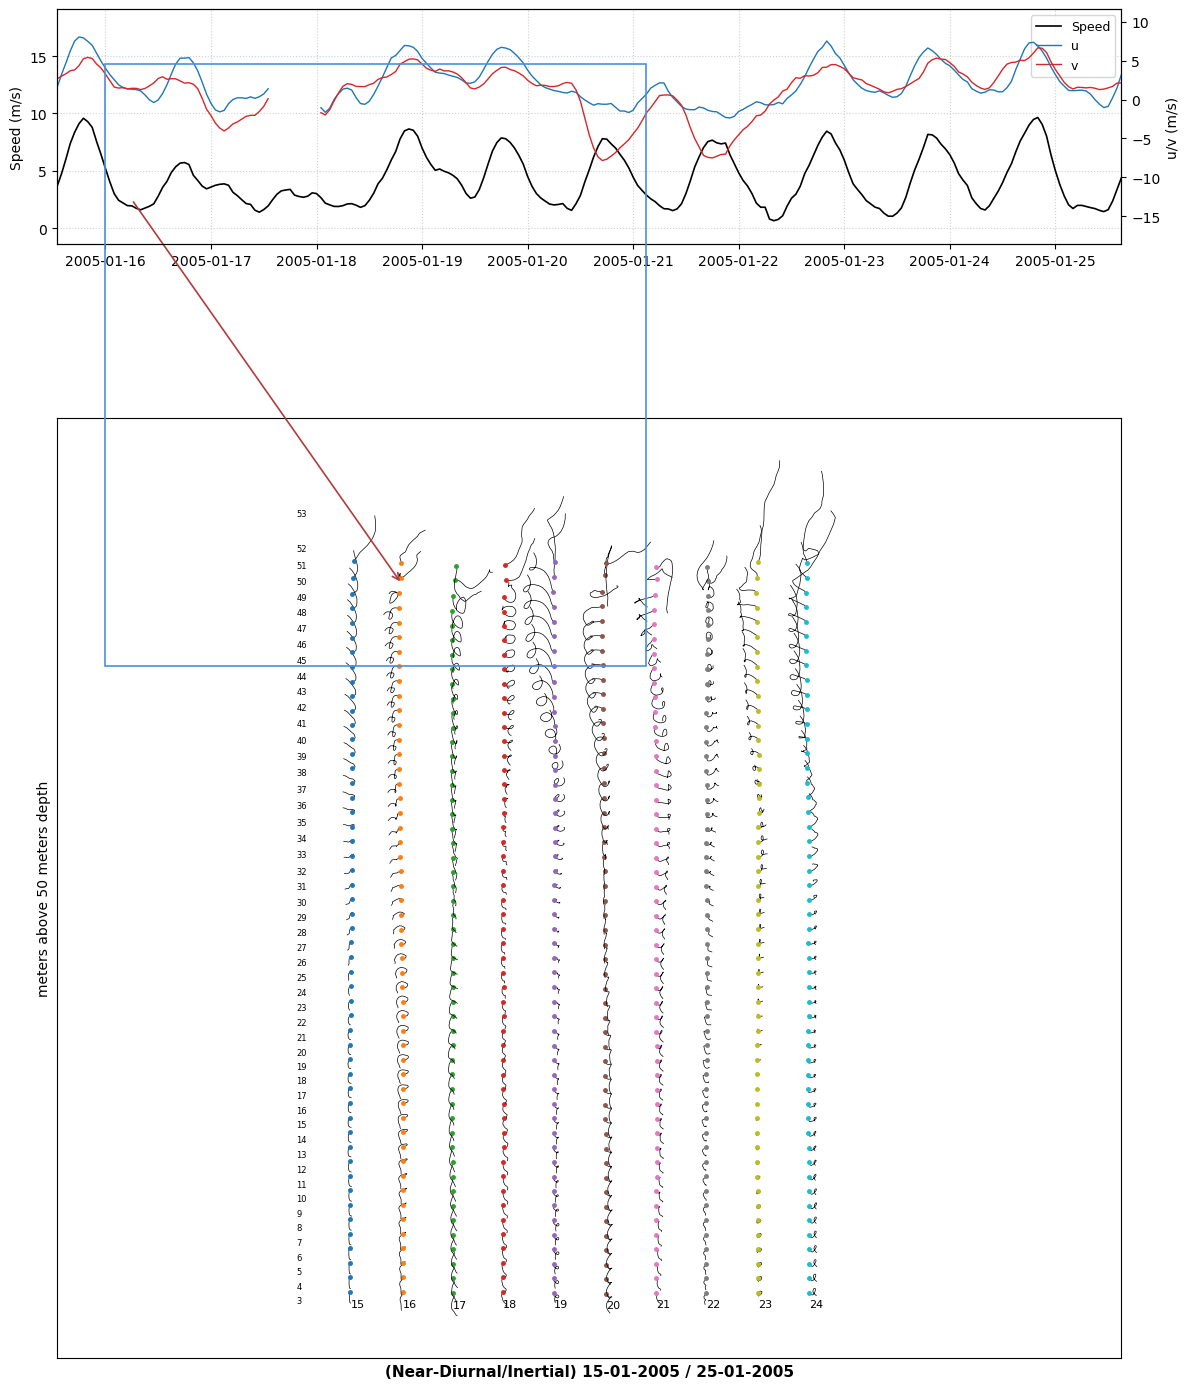

In [44]:
import matplotlib.dates as mdates
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter

# Create single figure with 2 vertically stacked subplots
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(12, 14),
    gridspec_kw={"height_ratios": [1, 4]},
    tight_layout=True,
)

# ==========================================
# TOP SUBPLOT: Time Series (Speed, U, V)
# ==========================================
# Left Y-axis: Total speed
line1 = ax1.plot(
    cs["time"],
    savgol_filter(cs["speed_ms"], 10, 2),
    color="black",
    linewidth=1.2,
    label="Speed",
)
ax1.set_ylabel("Speed (m/s)", color="black")
ax1.tick_params(axis="y", labelcolor="black")

# Right Y-axis: U and V components
ax1_twin = ax1.twinx()
line2 = ax1_twin.plot(
    cs["time"],
    savgol_filter(cs["u"], 10, 2),
    color="tab:blue",
    linewidth=1.0,
    label="u",
)
line3 = ax1_twin.plot(
    cs["time"],
    savgol_filter(cs["v"], 10, 2),
    color="tab:red",
    linewidth=1.0,
    label="v",
)
ax1_twin.set_ylabel("u/v (m/s)")

# Combined legend for top subplot
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right", frameon=True, fontsize=9)

ax1.set_xlim([dataB["time"][0], dataB["time"][-1]])
ax1.grid(True, linestyle=":", alpha=0.6)

# ==========================================
# BOTTOM SUBPLOT: Progressive Vector Diagram Waterfall
# ==========================================
for g in range(0, 51):
    for i in range(0, len(idx) - 1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u[z, g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(
                u[z, g], v[z, g], t1[z]
            )
            ax2.plot(x_km + 14 * i, y_km + 4 * g, linewidth=0.5, color="k")
            ax2.plot(
                x_km[0] + 14 * i,
                y_km[0] + 4 * g,
                linewidth=0.5,
                marker=".",
                markersize=5,
            )

            if g == 0:
                ax2.text(x_km[0] + 14 * i, y_km[0] - 4, idx[i], fontsize=8)

for g in range(0, 51):
    for i in range(0, 1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u[z, g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(
                u[z, g], v[z, g], t1[z]
            )
            ax2.text(
                -15,
                y_km[-1] + 4 * g,
                int(np.round(dataB["depth"][g])),
                fontsize=6,
            )
            del x_km, y_km, seg_ok, t_valid

ax2.set_aspect("equal", adjustable="box")
ax2.axis("tight")
ax2.set_xlabel(
    f'(Near-Diurnal/Inertial) {t1[0].strftime("%d-%m-%Y")} / {t1[-1].strftime("%d-%m-%Y")}',
    fontsize=11,
    weight="bold",
)
ax2.set_ylabel("meters above 50 meters depth", fontsize=10)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.grid(True)
ax2.axis("equal")

# ==========================================
# HIGHLIGHT RECTANGLE & CONNECTING ARROW
# ==========================================
# Blended transform: X in ax1 date coordinates, Y in figure-fraction coordinates
trans_box = transforms.blended_transform_factory(
    ax1.transData, fig.transFigure
)

# Date limits for the blue bounding rectangle (Jan 16 to Jan 21)
x_box_start = mdates.date2num(pd.Timestamp("2005-01-16 00:00"))
x_box_end = mdates.date2num(pd.Timestamp("2005-01-21 03:00"))

# Vertical bounds in figure coordinates (spans across the top panel gap into ax2)
y_box_bottom = 0.52
y_box_top = 0.95

# 1. Draw Blue Bounding Rectangle
rect = patches.Rectangle(
    (x_box_start, y_box_bottom),
    x_box_end - x_box_start,
    y_box_top - y_box_bottom,
    linewidth=1.2,
    edgecolor="#4a90e2",  # Bright blue outline
    facecolor="none",
    transform=trans_box,
    zorder=10,
    clip_on=False,
)
fig.patches.append(rect)

# 2. Add Red Arrow pointing from top time series down into PVD trajectory loop
arrow_start_x = mdates.date2num(pd.Timestamp("2005-01-16 06:00"))
arrow_start_y = 2.5  # In ax1 speed units

ax2.annotate(
    "",
    xy=(14, 195),  # Target location in ax2 data coordinates
    xytext=(arrow_start_x, arrow_start_y),
    textcoords=ax1.transData,
    xycoords=ax2.transData,
    arrowprops=dict(
        arrowstyle="->",
        color="#b23b3b",  # Dark red/brown
        linewidth=1.2,
        mutation_scale=12,
    ),
    zorder=15,
)

plt.show()

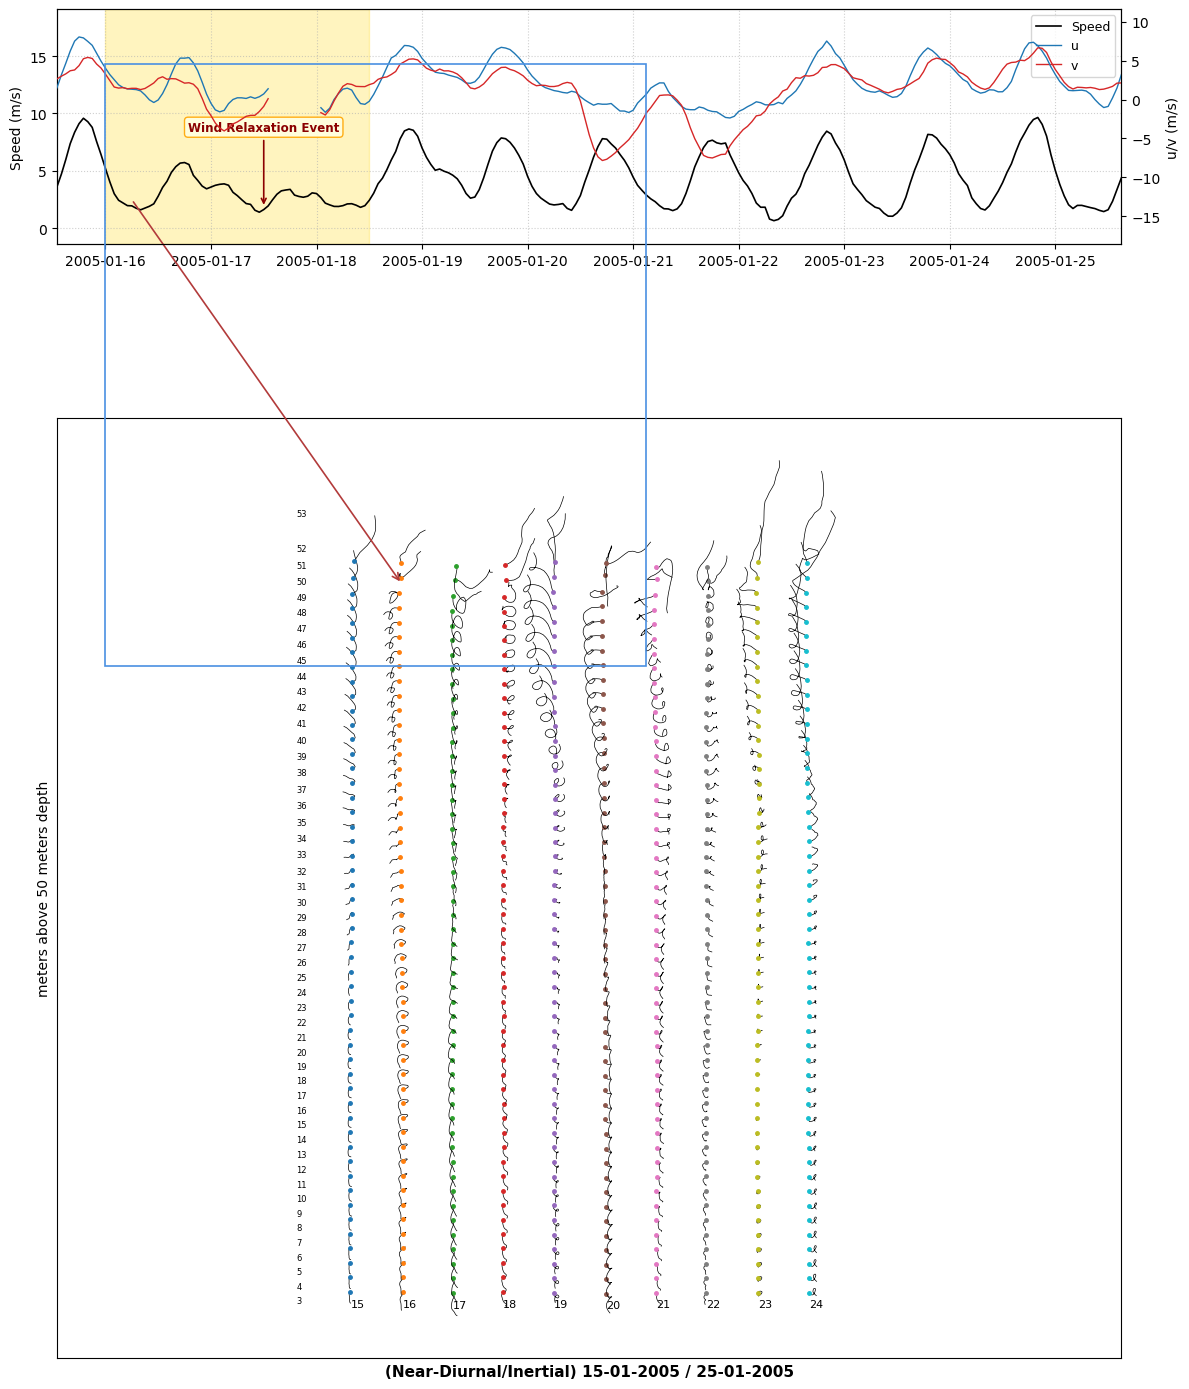

In [45]:
import matplotlib.dates as mdates
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter

# Create single figure with 2 vertically stacked subplots
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(12, 14),
    gridspec_kw={"height_ratios": [1, 4]},
    tight_layout=True,
)

# ==========================================
# TOP SUBPLOT: Time Series (Speed, U, V)
# ==========================================
# 1. WIND RELAXATION WINDOW HIGHLIGHT (Jan 16 00:00 - Jan 18 12:00)
relax_start = pd.Timestamp("2005-01-16 00:00")
relax_end = pd.Timestamp("2005-01-18 12:00")

ax1.axvspan(
    relax_start,
    relax_end,
    color="gold",
    alpha=0.25,
    zorder=1,
    label="Wind Relaxation Event",
)

# 2. Time-series velocity lines
line1 = ax1.plot(
    cs["time"],
    savgol_filter(cs["speed_ms"], 10, 2),
    color="black",
    linewidth=1.2,
    label="Speed",
    zorder=3,
)
ax1.set_ylabel("Speed (m/s)", color="black")
ax1.tick_params(axis="y", labelcolor="black")

ax1_twin = ax1.twinx()
line2 = ax1_twin.plot(
    cs["time"],
    savgol_filter(cs["u"], 10, 2),
    color="tab:blue",
    linewidth=1.0,
    label="u",
    zorder=3,
)
line3 = ax1_twin.plot(
    cs["time"],
    savgol_filter(cs["v"], 10, 2),
    color="tab:red",
    linewidth=1.0,
    label="v",
    zorder=3,
)
ax1_twin.set_ylabel("u/v (m/s)")

# Annotate Wind Relaxation Event
ax1.annotate(
    "Wind Relaxation Event",
    xy=(mdates.date2num(pd.Timestamp("2005-01-17 12:00")), 1.8),
    xytext=(mdates.date2num(pd.Timestamp("2005-01-17 12:00")), 8.5),
    arrowprops=dict(arrowstyle="->", color="darkred", lw=1.2),
    ha="center",
    fontsize=8.5,
    fontweight="bold",
    color="darkred",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="lightyellow",
        edgecolor="orange",
        alpha=0.9,
    ),
    zorder=10,
)

# Combined legend for top subplot
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right", frameon=True, fontsize=9)

ax1.set_xlim([dataB["time"][0], dataB["time"][-1]])
ax1.grid(True, linestyle=":", alpha=0.6)

# ==========================================
# BOTTOM SUBPLOT: Progressive Vector Diagram Waterfall
# ==========================================
for g in range(0, 51):
    for i in range(0, len(idx) - 1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u[z, g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(
                u[z, g], v[z, g], t1[z]
            )
            ax2.plot(x_km + 14 * i, y_km + 4 * g, linewidth=0.5, color="k")
            ax2.plot(
                x_km[0] + 14 * i,
                y_km[0] + 4 * g,
                linewidth=0.5,
                marker=".",
                markersize=5,
            )

            if g == 0:
                ax2.text(x_km[0] + 14 * i, y_km[0] - 4, idx[i], fontsize=8)

for g in range(0, 51):
    for i in range(0, 1):
        z = np.where(doy == idx[i])[0]
        if np.isnan(u[z, g]).sum() < 1:
            x_km, y_km, seg_ok, t_valid = progressive_vector(
                u[z, g], v[z, g], t1[z]
            )
            ax2.text(
                -15,
                y_km[-1] + 4 * g,
                int(np.round(dataB["depth"][g])),
                fontsize=6,
            )
            del x_km, y_km, seg_ok, t_valid

ax2.set_aspect("equal", adjustable="box")
ax2.axis("tight")
ax2.set_xlabel(
    f'(Near-Diurnal/Inertial) {t1[0].strftime("%d-%m-%Y")} / {t1[-1].strftime("%d-%m-%Y")}',
    fontsize=11,
    weight="bold",
)
ax2.set_ylabel("meters above 50 meters depth", fontsize=10)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.grid(True)
ax2.axis("equal")

# ==========================================
# HIGHLIGHT RECTANGLE & CONNECTING ARROW
# ==========================================
trans_box = transforms.blended_transform_factory(
    ax1.transData, fig.transFigure
)

x_box_start = mdates.date2num(pd.Timestamp("2005-01-16 00:00"))
x_box_end = mdates.date2num(pd.Timestamp("2005-01-21 03:00"))

y_box_bottom = 0.52
y_box_top = 0.95

# Blue Bounding Rectangle
rect = patches.Rectangle(
    (x_box_start, y_box_bottom),
    x_box_end - x_box_start,
    y_box_top - y_box_bottom,
    linewidth=1.2,
    edgecolor="#4a90e2",
    facecolor="none",
    transform=trans_box,
    zorder=10,
    clip_on=False,
)
fig.patches.append(rect)

# Red Connecting Arrow
arrow_start_x = mdates.date2num(pd.Timestamp("2005-01-16 06:00"))
arrow_start_y = 2.5

ax2.annotate(
    "",
    xy=(14, 195),
    xytext=(arrow_start_x, arrow_start_y),
    textcoords=ax1.transData,
    xycoords=ax2.transData,
    arrowprops=dict(
        arrowstyle="->",
        color="#b23b3b",
        linewidth=1.2,
        mutation_scale=12,
    ),
    zorder=15,
)

plt.show()